![Original climate-globe illustration introducing Global temperature: from Pulse to Python; illustrative, not a data map](assets/atlas-splash.png)

# 30 · Global temperature: from Pulse to Python

**Guiding question:** How do global air and ocean records answer different questions?

**Data:** Real archived C3S/ECMWF ERA5 global air and ocean monthly CSVs; derived annual summaries  
**Time:** 20–35 minutes · **Prerequisites:** basic Python; run cells from top to bottom.  
**Author:** JupyterLite-C3S-Atlas contributors (AI assisted) · **Created/updated:** 2026-11-20  
**Inputs:** bundled reference files and/or seeded examples specified below. **Outputs:** tables, figures, and any explicitly named local exports; source data are not modified.  
**Runtime:** Python/Pyodide; NumPy, pandas, Matplotlib, Plotly; versions and tests are recorded in the validation report.  
**Change log:** initial educational chapter. **Contact:** [repository issues](https://github.com/jltobias/JupyterLite-C3S-Atlas/issues).

[Open in JupyterLite Lab](https://jltobias.github.io/JupyterLite-C3S-Atlas/lite/lab/index.html?path=30-global-pulse-workshop.ipynb) · [Official Atlas](https://atlas.climate.copernicus.eu/)


## Read the evidence

Use the official app as a companion to the calculation: choose a quantity
        in Python, open its matching Pulse selection, and compare the displayed metadata.
        Our source files are archived on 20 November 2026; the official app keeps evolving.
        Share-link parameters were checked against the published Pulse application on
        that date. If a future version changes them, choose the same settings manually
        and copy the app's own Share link.

        “Global” air temperature covers land and ocean at all latitudes, whereas this
        global SST export covers ocean points from 60°S to 60°N. Different domains and
        variables mean the series should not be subtracted as though they were repeated
        measurements of the same quantity. Both anomalies below use 1991–2020.

        Build complete annual summaries by weighting monthly means by days per month.
        Omit incomplete years explicitly. This is our stated aggregation of the supplied
        monthly product, not a claim to reproduce every detail of the official annual view.
        A single annual anomaly is also different from a sustained long-term warming level.
        Consult the trend monitor's method before comparing its 1.5 °C context.

## Start the browser lab

Run this setup cell once. First load needs internet for the Python runtime and packages. The remaining lesson uses bundled data. If a 3D view is unavailable, use the 2D/table alternative. Download your edited notebook before clearing browser storage.

In [1]:
# Install only in the browser kernel; desktop dependencies come from requirements.txt.
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "pandas", "matplotlib", "plotly==6.5.0"])

import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from IPython.display import display
from atlas_helpers import (
    DATA, SYNTHETIC, COLORS, show, monthly_demo, anomalies, regular_grid,
    area_mean, coastlines, map_figure, globe_figure, warming_levels, load_monthly_csv,
)
print("Ready. Browser edits live in this browser; download work you want to keep.")


Ready. Browser edits live in this browser; download work you want to keep.


## Open two complementary official views

In [2]:
from app_helpers import pulse_link, complete_years, read_pulse_monthly_csv, compare_pulse_exports, apps_catalogue
from pulse_helpers import load_pulse, ANOM, REL
from IPython.display import Markdown
air = load_pulse("global", variable="t2m")
ocean = load_pulse("60S-60N_ocean")
display(pd.DataFrame([
    {"series":"Global 2 m air", "start":str(air.date.min().date()), "end":str(air.date.max().date()), "domain":"All latitudes, land + ocean"},
    {"series":"Global SST", "start":str(ocean.date.min().date()), "end":str(ocean.date.max().date()), "domain":"Ocean, 60°S–60°N"},
]))
air_url = pulse_link(variable="t2m", region="global", quantity="anomaly", date="2024-01-01", aggregation="annual")
sst_url = pulse_link(region="global", quantity="anomaly", date="2024-01-01", aggregation="annual")
display(Markdown(f"[Official Pulse: global air, 2024 annual anomaly]({air_url}) · [Official Pulse: global SST, 2024 annual anomaly]({sst_url})"))

,series,start,end,domain
0,Global 2 m air,1940-01-01,2026-10-01,"All latitudes, land + ocean"
1,Global SST,1979-01-01,2026-10-01,"Ocean, 60°S–60°N"


[Official Pulse: global air, 2024 annual anomaly](https://pulse.climate.copernicus.eu/?variable=2t&region=global&series=anomaly&map=anomaly&aggregation=annual&date=2024-01-01) · [Official Pulse: global SST, 2024 annual anomaly](https://pulse.climate.copernicus.eu/?variable=sst&region=global&series=anomaly&map=anomaly&aggregation=annual&date=2024-01-01)

## Compare complete years with visible spatial domains

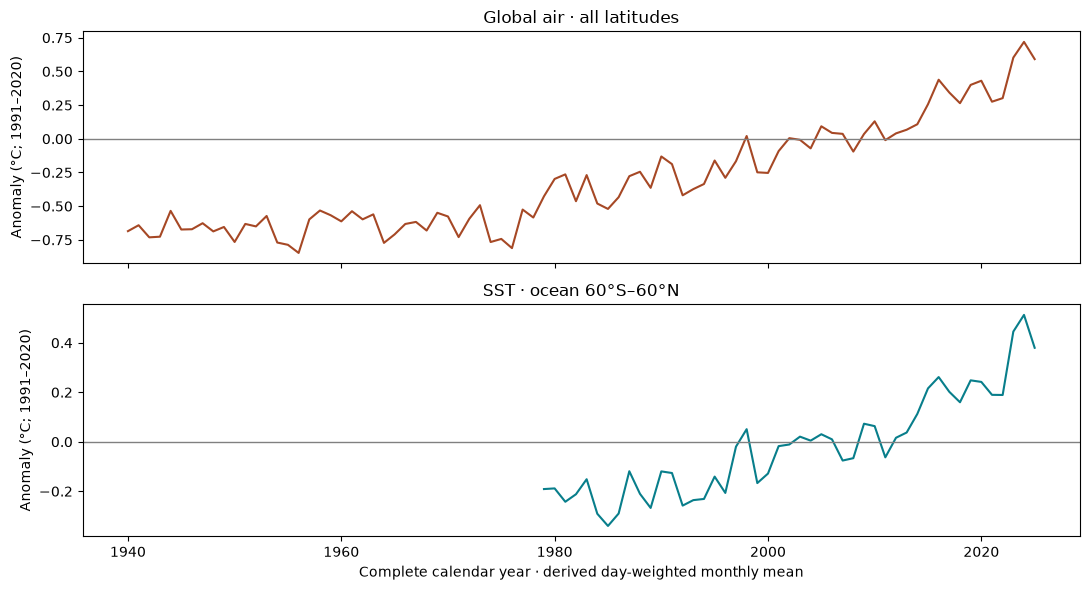

,year,global_air_anomaly_c,months,days
81,2021,0.275418,12,365
82,2022,0.301835,12,365
83,2023,0.602751,12,365
84,2024,0.719363,12,366
85,2025,0.591419,12,365


Incomplete 2026 is excluded from these annual curves.


In [3]:
annual_air = complete_years(air, ANOM)
annual_ocean = complete_years(ocean, ANOM)
fig, axes = plt.subplots(2,1,figsize=(11,6),sharex=True)
for ax, annual, label, colour in [(axes[0],annual_air,"Global air · all latitudes","#a64825"), (axes[1],annual_ocean,"SST · ocean 60°S–60°N","#087e8b")]:
    ax.plot(annual.year, annual.value, color=colour)
    ax.axhline(0,color="gray",lw=1)
    ax.set(title=label, ylabel="Anomaly (°C; 1991–2020)")
axes[1].set_xlabel("Complete calendar year · derived day-weighted monthly mean")
plt.tight_layout(); plt.show()
display(annual_air.tail().rename(columns={"value":"global_air_anomaly_c"}))
print("Incomplete 2026 is excluded from these annual curves.")

## Separate annual monitoring from a long-term indicator

In [4]:
ranked = annual_air.assign(rank=annual_air.value.rank(method="min",ascending=False).astype(int))
year = 2024
row = ranked.loc[ranked.year == year].iloc[0]
card = {"year":year,"derived_annual_anomaly_c":round(float(row.value),4),
        "rank_among_complete_years":int(row["rank"]),"number_of_years":len(ranked),
        "baseline":"1991–2020","method":"Day-weight supplied monthly anomalies; complete years only",
        "scope":"Global 2 m air; descriptive archive rank",
        "not_inferred":"Date of sustained 1.5 °C warming; attribution of any local event"}
display(pd.Series(card).to_frame("Monitoring card"))
catalogue = apps_catalogue()
monitor = next(app for app in catalogue["entries"] if app["id"] == "global-temperature-trend-monitor")
display(Markdown(f"[Compare with the official global temperature trend monitor]({monitor['url']})"))

,Monitoring card
year,2024
derived_annual_anomaly_c,0.7194
rank_among_complete_years,1
number_of_years,86
baseline,1991–2020
method,Day-weight supplied monthly anomalies; complet...
scope,Global 2 m air; descriptive archive rank
not_inferred,Date of sustained 1.5 °C warming; attribution ...


[Compare with the official global temperature trend monitor](https://apps.climate.copernicus.eu/global-temperature-trend-monitor/)

## Try it and explain

Choose a different complete year, open its official annual view, and record any difference in rounding or aggregation. Then compare the reference period and method used by the trend monitor.

**Interpretation check:** A fair comparison needs the same variable, spatial support, reference period, averaging rule, and archive version. An annual anomaly alone does not establish a sustained global warming level.

## Transfer to the official tools

In Pulse, switch between daily, monthly, and annual views. In the trend monitor, read its method before comparing the numerical indicator. Keep both source links with your evidence card.

Record the selections, source version, units, periods, and uncertainty legend. These independent lessons do not duplicate every production workflow in the official tools.

## Sources and credit

- [C3S Atlas dataset and DOI](https://doi.org/10.24381/cds.h35hb680)
- [CSIC / Predictia Atlas user guide](https://confluence.ecmwf.int/spaces/CKB/pages/394237545/Copernicus+Interactive+Climate+Atlas+User+Guide)
- [Official C3S Atlas User Tools and contributors](https://ecmwf-projects.github.io/c3s-atlas/)
- [Official Climate Pulse](https://pulse.climate.copernicus.eu/)
- [Copernicus Data Stores Applications](https://apps.climate.copernicus.eu/)
- [ERA5 monthly dataset](https://doi.org/10.24381/cds.f17050d7)
- [Pulse methodology](https://pulse.climate.copernicus.eu/faqs)
- [Global temperature trend monitor overview](https://apps.climate.copernicus.eu/overview?app=global-temperature-trend-monitor)

Original teaching text and code; original AI-generated splash illustration. Real reference files retain their source licences. Synthetic examples are not Copernicus measurements. See [credits](credits.md) and [data guide](data-guide.md).

**Continue:** [Download, import, and audit a Pulse export](31-pulse-download-roundtrip.ipynb)